# Investigating Silence in Written Text and Large Language Models

**Panagiotis Ermeidis · M.A. thesis, University of Konstanz, 2026**

Can the words of a subtitle line tell you that a long silence will follow? A pause of 700 ms or more counts as a silence (class 1).
287 linguistic features of the line before the pause are compared with embeddings of BERT-Large and Mistral-7B, and then used to
describe the lines the two models get wrong.

| Section | Thesis |
|---|---|
| 1 Data | chapter 4 |
| 2 Features | chapter 5 |
| 3 Feature selection | 7.3.1, 8.1 |
| 4 Baseline and feature models | 8.2 |
| 5 Feature groups | 8.2.2 |
| 6 Transformer embeddings | 8.3 |
| 7 Error analysis | 8.4 |
| 8 All models | 8.5 |
| 9 Checks made after the thesis | – |

Sections 2–5 and 7 run from the files in `data/`. The film subtitles are copyrighted and the embeddings are large, so neither is in this
repository. The cells that need them are marked; their saved output is from a run with the files in place.

## Setup

```
pip install -r requirements.txt
python -m spacy download en_core_web_sm
```

In [1]:
import os, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nltk
for package in ("stopwords", "punkt", "punkt_tab"):
    nltk.download(package, quiet=True)

from silence import error_analysis, models, subtitles
from silence.feature_groups import GROUPS
from silence.models import TARGET

# ── Paths: all in one place ──────────────────────────────────
DATA = Path("data")
RESULTS = Path("results")
SUBTITLES = Path(os.environ.get("SILENCE_SUBTITLES", DATA / "subtitles"))      # the .srt files, see data/README.md
EMBEDDINGS = Path(os.environ.get("SILENCE_EMBEDDINGS", DATA / "embeddings"))   # output of the two scripts in gpu/

HAVE_SUBTITLES = any(SUBTITLES.glob("*.srt"))
HAVE_MISTRAL = (EMBEDDINGS / "mistral_embeddings.npz").exists()
print("subtitles:", HAVE_SUBTITLES, "| Mistral embeddings:", HAVE_MISTRAL)

subtitles: True | Mistral embeddings: True


[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1002)>
[nltk_data] Error loading punkt: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1002)>
[nltk_data] Error loading punkt_tab: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1002)>


## 1 Data

Each subtitle block has a start and an end time, so the pause between two lines can be measured:
`gap = start of the next line − end of this line`. Before that, blocks that belong to one sentence are joined, because a break inside a
sentence is not a pause between turns. *Needs the subtitles.*

In [2]:
if HAVE_SUBTITLES:
    pairs = subtitles.build_pairs(SUBTITLES)
    balanced = subtitles.balance(pairs)
    print(f"{len(pairs):,} pairs from {pairs['file_name'].nunique()} films")
    print(f"{len(balanced):,} pairs from {balanced['file_name'].nunique()} films after balancing:", balanced[TARGET].value_counts().to_dict())

18,584 pairs from 12 films
12,970 pairs from 11 films after balancing: {0: 6485, 1: 6485}


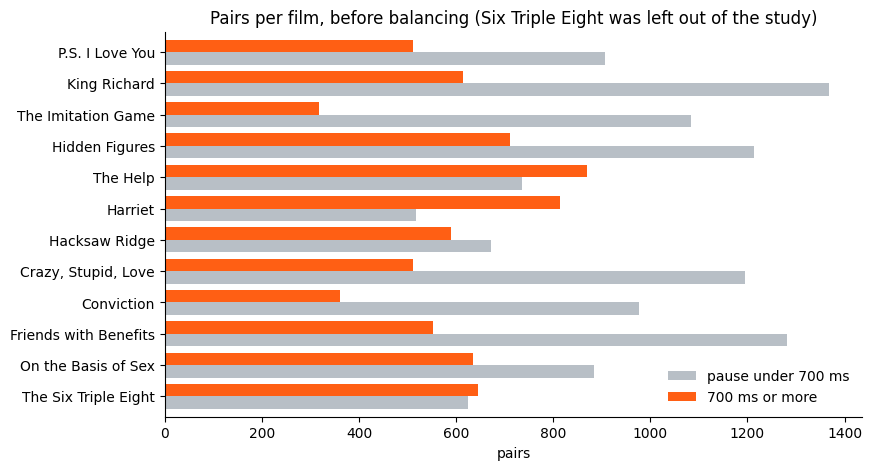

In [3]:
if HAVE_SUBTITLES:
    counts = pairs.groupby(["file_name", TARGET]).size().unstack()
    counts.index = [subtitles.FILMS[f] for f in counts.index]
    ax = counts.plot.barh(color=["#b8bfc6", "#ff5f14"], figsize=(9, 5), width=0.8)
    ax.legend(["pause under 700 ms", "700 ms or more"], frameon=False)
    ax.set(xlabel="pairs", ylabel="", title="Pairs per film, before balancing (Six Triple Eight was left out of the study)")
    ax.spines[["top", "right"]].set_visible(False)

The balanced set is split once, 80 / 10 / 10, with both classes equally frequent in each part. The feature tables in `data/` are these
three parts.

In [4]:
if HAVE_SUBTITLES:
    from sklearn.model_selection import train_test_split
    train, rest = train_test_split(balanced, test_size=0.20, random_state=42, stratify=balanced[TARGET])
    validation, test = train_test_split(rest, test_size=0.50, random_state=42, stratify=rest[TARGET])
    pair_tables = {"train": train, "validation": validation, "test": test}
    (DATA / "pairs").mkdir(exist_ok=True)   # input of the scripts in gpu/; stays on this computer (.gitignore)
    for name, table in pair_tables.items():
        saved = pd.read_csv(DATA / f"features_{name}.csv.gz", usecols=["gap_sec", TARGET])
        same = np.allclose(saved["gap_sec"], table["gap_sec"]) and (saved[TARGET].to_numpy() == table[TARGET].to_numpy()).all()
        print(f"{name:<11}{len(table):>7,} pairs, same rows as the feature table: {same}")
        table.to_csv(DATA / "pairs" / f"{name}.csv", index=False)

train       10,376 pairs, same rows as the feature table: True
validation   1,297 pairs, same rows as the feature table: True
test         1,297 pairs, same rows as the feature table: True


## 2 Features

All features describe the line *before* the pause. That is what a system has when the pause begins.

In [5]:
raw_train = pd.read_csv(DATA / "features_train.csv.gz", dtype={"film": str})
tables, features = models.load_features(DATA)
train, validation, test = tables["train"], tables["validation"], tables["test"]
trainval = pd.concat([train, validation], ignore_index=True)

print({name: len(group) for name, group in GROUPS.items()}, "→", len(features), "features")
print("train", len(train), "| validation", len(validation), "| test", len(test))

{'Syntactic': 172, 'Lexical-semantic': 27, 'Structural': 20, 'Affect': 68} → 287 features
train 10376 | validation 1297 | test 1297


One line, read by the feature code (the line is made up):

In [6]:
from silence.features import extract

line = "Could you wait outside for a minute... please?"
values = extract(line, duration=2.9)
shown = ["syllables_per_second", "total_number_of_words", "num_question_marks", "num_politeness", "tree_depth_max",
         "n_main_clauses", "right_branching_count", "ends_at_clause_boundary", "ellipsis_score", "is_bare_wh"]
pd.Series({name: values[name] for name in shown}, name=line).round(2).to_frame()

,Could you wait outside for a minute... please?
syllables_per_second,3.45
total_number_of_words,10.00
num_question_marks,1.00
num_politeness,2.00
tree_depth_max,3.00
n_main_clauses,1.00
right_branching_count,6.00
ends_at_clause_boundary,1.00
ellipsis_score,1.00
is_bare_wh,0.00


The code in `silence/features.py` computes 211 of the 287 features. The check below computes them again for random lines and
compares them with the table. The other 76 (affect features, discourse connectives, hedges and intensifiers) are in the table as values
only. *Needs the subtitles.*

In [7]:
if HAVE_SUBTITLES:
    saved = pd.read_csv(DATA / "features_test.csv.gz")
    sample = test.sample(100, random_state=1).index
    again = pd.DataFrame([extract(row.sub1_text, row.sub1_end_sec - row.sub1_start_sec)
                          for row in pair_tables["test"].iloc[sample].itertuples()])
    equal = np.isclose(again.to_numpy(float), saved.loc[sample, again.columns].to_numpy(float), atol=1e-6).all(axis=0)
    print(f"{equal.sum()} of {again.shape[1]} recomputed features are identical on {len(sample)} lines")

211 of 211 recomputed features are identical on 100 lines


**Speech rate** is the strongest single feature: lines before a long silence are slower. It is the one feature that also uses the time
the line is on screen, not only its words.

In [8]:
everything = pd.concat([pd.read_csv(DATA / f"features_{n}.csv.gz") for n in ("train", "validation", "test")])
everything.groupby(TARGET)["syllables_per_second"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
silence_label,,,,,,,,
0,6485.0,4.06,1.70,0.0,2.89,4.05,5.17,11.36
1,6485.0,3.29,1.57,0.0,2.18,3.28,4.39,9.39


## 3 Feature selection

L1-penalised logistic regression (LASSO) sets the weights of weak or redundant features to zero.

In [9]:
selection = models.lasso(train[features].to_numpy(), train[TARGET])
weights = pd.Series(np.abs(selection.coef_[0]), index=features).sort_values(ascending=False)
selected = weights[weights > 0].index.tolist()
print(f"{len(selected)} of {len(features)} features kept")
weights.head(10).round(4).to_frame("|weight|")

82 of 287 features kept


,|weight|
syllables_per_second,0.5094
simple_punctuations_variation,0.1243
total_number_of_unique_interjections,0.0933
num_question_marks,0.0836
total_number_of_unique_punctuations,0.0830
nsubjpass,0.0547
np_length_mean,0.0521
dep_distance_amod_mean,0.0507
nmod,0.0495
simple_proper_nouns_variation,0.0490


In [10]:
thesis_selection = pd.read_csv(RESULTS / "selected_features.csv")["feature"].tolist()
print("same 82 features as in the thesis:", set(selected) == set(thesis_selection))
selected = thesis_selection   # same features, in the order of the thesis run

same 82 features as in the thesis: True


## 4 Baseline and feature models

Linear SVMs. `C` is chosen by 5-fold cross-validation on train + validation; the test set is scored once. The baseline gets word
counts (TF-IDF). As in the thesis, it is trained on both lines of a pair and tested on the first line only; section 9 shows what it
scores when training and test match. *The baseline needs the subtitles.*

In [11]:
results = {}

def run(name, columns):
    svm, C = models.tune_linear_svm(trainval[columns].to_numpy(), trainval[TARGET])
    X = test[columns].to_numpy()
    results[name] = {"inputs": len(columns), "C": C, **models.scores(test[TARGET], svm.predict(X), svm.decision_function(X))}
    return svm

run("All 287 features, linear SVM", features)
feature_svm = run("82 selected features, linear SVM", selected)

if HAVE_SUBTITLES:
    first = {n: t["sub1_text"].to_numpy() for n, t in pair_tables.items()}
    both = {n: (t["sub1_text"] + " " + t["sub2_text"]).to_numpy() for n, t in pair_tables.items()}
    baseline, C = models.tune_linear_svm(np.concatenate([both["train"], both["validation"]]), trainval[TARGET], models.with_tfidf)
    results["TF-IDF baseline, linear SVM"] = {
        "inputs": len(baseline[0].vocabulary_), "C": C,
        **models.scores(test[TARGET], baseline.predict(first["test"]), baseline.decision_function(first["test"]))}

pd.DataFrame(results).T.round(4)

,inputs,C,accuracy,roc_auc,macro_f1,precision_0,recall_0,precision_1,recall_1
"All 287 features, linear SVM",287.0,0.010,0.6122,0.6794,0.6117,0.6209,0.5778,0.6046,0.6466
"82 selected features, linear SVM",82.0,0.001,0.6268,0.6779,0.6264,0.6364,0.5932,0.6185,0.6605
"TF-IDF baseline, linear SVM",32483.0,0.100,0.5705,0.6084,0.5686,0.5821,0.5023,0.5617,0.6389


In [12]:
pd.Series(np.abs(feature_svm.coef_[0]), index=selected, name="|weight|").sort_values(ascending=False).head(10).round(3).to_frame()

,|weight|
syllables_per_second,0.234
simple_punctuations_variation,0.064
total_number_of_unique_punctuations,0.050
ends_at_clause_boundary,0.048
num_question_marks,0.048
np_length_mean,0.046
total_number_of_nouns,0.039
left_branching_ratio,0.030
simple_proper_nouns_variation,0.030
nsubjpass,0.030


## 5 Feature groups

Each group on its own, then the full set with one group left out. (The models of this section are tuned and trained on the training
part; the thesis text says train + validation.)

In [13]:
def group_scores(columns):
    svm, C = models.tune_linear_svm(train[columns].to_numpy(), train[TARGET])
    X = test[columns].to_numpy()
    s = models.scores(test[TARGET], svm.predict(X), svm.decision_function(X))
    return {"features": len(columns), "C": C, "accuracy": s["accuracy"], "roc_auc": s["roc_auc"], "macro_f1": s["macro_f1"]}

groups_alone = pd.DataFrame({name: group_scores(columns) for name, columns in GROUPS.items()}).T
groups_alone.round(4).to_csv(RESULTS / "feature_groups.csv")
groups_alone.round(4)

,features,C,accuracy,roc_auc,macro_f1
Syntactic,172.0,0.001,0.6207,0.6705,0.6202
Lexical-semantic,27.0,0.001,0.5998,0.6356,0.5996
Structural,20.0,0.100,0.5968,0.6281,0.5949
Affect,68.0,0.010,0.5790,0.6099,0.5780


In [14]:
left_out = {"nothing": group_scores(sum((GROUPS[g] for g in ("Lexical-semantic", "Structural", "Affect", "Syntactic")), []))}
for name in GROUPS:
    left_out[name] = group_scores(sum((GROUPS[g] for g in ("Lexical-semantic", "Structural", "Affect", "Syntactic") if g != name), []))
left_out = pd.DataFrame(left_out).T.rename_axis("left out")
left_out.round(4).to_csv(RESULTS / "feature_groups_left_out.csv")
left_out.round(4)

,features,C,accuracy,roc_auc,macro_f1
left out,,,,,
nothing,287.0,0.001,0.6145,0.6765,0.6142
Syntactic,115.0,0.100,0.6045,0.6492,0.6043
Lexical-semantic,260.0,0.001,0.6199,0.6742,0.6196
Structural,267.0,0.001,0.6176,0.6792,0.6172
Affect,219.0,0.001,0.6083,0.6718,0.6081


## 6 Transformer embeddings

`gpu/finetune_bert.py` fine-tunes BERT-Large and saves the [CLS] vectors of its last four layers; `gpu/embed_mistral.py` takes the mean
of the last layer of the frozen Mistral-7B. Both read **both lines of the pair**, so they also see the reply. An SVM is trained on top.
*The Mistral part needs the embeddings. The BERT embeddings were not kept, so the BERT rows are the numbers of the thesis run.*

In [15]:
if HAVE_MISTRAL:
    z = np.load(EMBEDDINGS / "mistral_embeddings.npz")
    for kernel in ("linear", "rbf"):
        svm = models.embedding_svm(kernel).fit(z["train_embeddings"], z["y_train"])
        predicted, score = svm.predict(z["test_embeddings"]), svm.decision_function(z["test_embeddings"])
        name = "Mistral-7B, linear SVM" if kernel == "linear" else "Mistral-7B, RBF SVM"
        results[name] = {"inputs": z["train_embeddings"].shape[1], "C": 1.0, **models.scores(z["y_test"], predicted, score)}
        if kernel == "linear":
            saved = pd.read_csv(DATA / "predictions_mistral_linear.csv")["predicted"].to_numpy()
            print("test lines predicted as in the thesis run:", (saved == predicted).sum(), "of", len(saved))
    display(pd.DataFrame({k: v for k, v in results.items() if k.startswith("Mistral")}).T.round(4))

test lines predicted as in the thesis run: 1297 of 1297


,inputs,C,accuracy,roc_auc,macro_f1,precision_0,recall_0,precision_1,recall_1
"Mistral-7B, linear SVM",4096.0,1.0,0.5852,0.6296,0.5852,0.5850,0.5886,0.5854,0.5818
"Mistral-7B, RBF SVM",4096.0,1.0,0.6677,0.7254,0.6675,0.6775,0.6410,0.6589,0.6944


In [16]:
bert = pd.read_csv(DATA / "predictions_bert_linear.csv")
results["BERT-Large, linear SVM"] = {"inputs": 4096, "C": 1.0, **models.scores(bert[TARGET], bert["predicted"], bert["score"])}
thesis_run = pd.read_csv(RESULTS / "transformers_thesis_run.csv", index_col=0)
results["BERT-Large, RBF SVM"] = thesis_run.loc["BERT-Large, RBF SVM"].to_dict()
for name in thesis_run.index:            # without the embeddings, the Mistral rows come from the thesis run too
    results.setdefault(name, thesis_run.loc[name].to_dict())
thesis_run

,inputs,C,accuracy,roc_auc,macro_f1,precision_0,recall_0,precision_1,recall_1
model,,,,,,,,,
"BERT-Large, linear SVM",4096,1.0,0.5605,0.5950,0.5605,0.5609,0.5609,0.5602,0.5602
"BERT-Large, RBF SVM",4096,1.0,0.6500,0.7044,0.6493,0.6650,0.6055,0.6374,0.6944
"Mistral-7B, linear SVM",4096,1.0,0.5852,0.6296,0.5852,0.5850,0.5886,0.5854,0.5818
"Mistral-7B, RBF SVM",4096,1.0,0.6677,0.7254,0.6675,0.6775,0.6410,0.6589,0.6944


## 7 Error analysis

For each class, the test lines a model gets right are compared with those it gets wrong, on the 82 selected features (Welch's t-test;
chi-squared for yes/no features). This uses the **linear** versions of both models, whose accuracy is 0.56 and 0.59.

82 features are tested at once, so about 4 would fall below 0.05 by chance. The plots therefore also show which features pass a Holm
correction (dark bars). The thesis reports the uncorrected values.

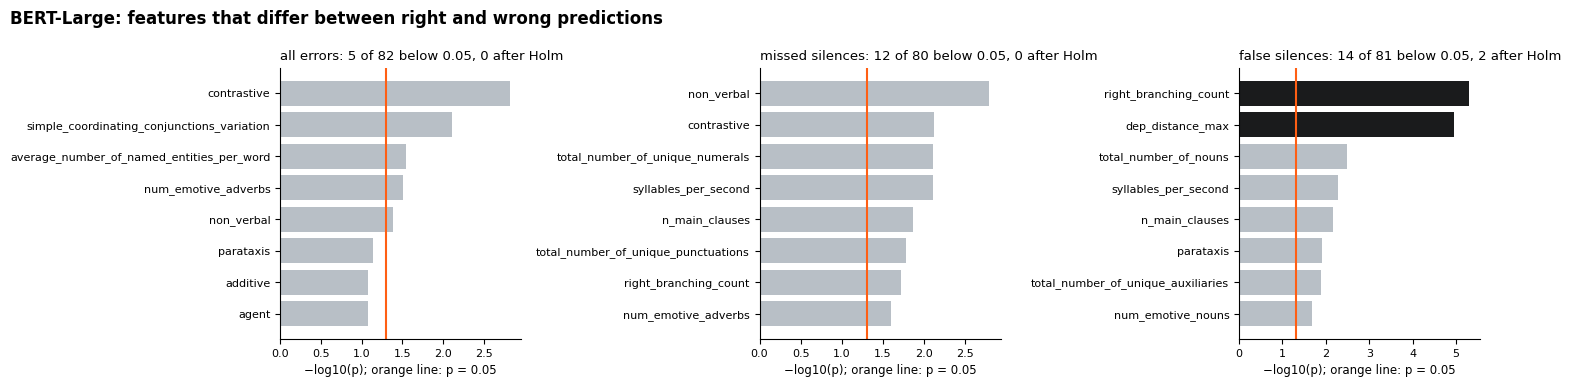

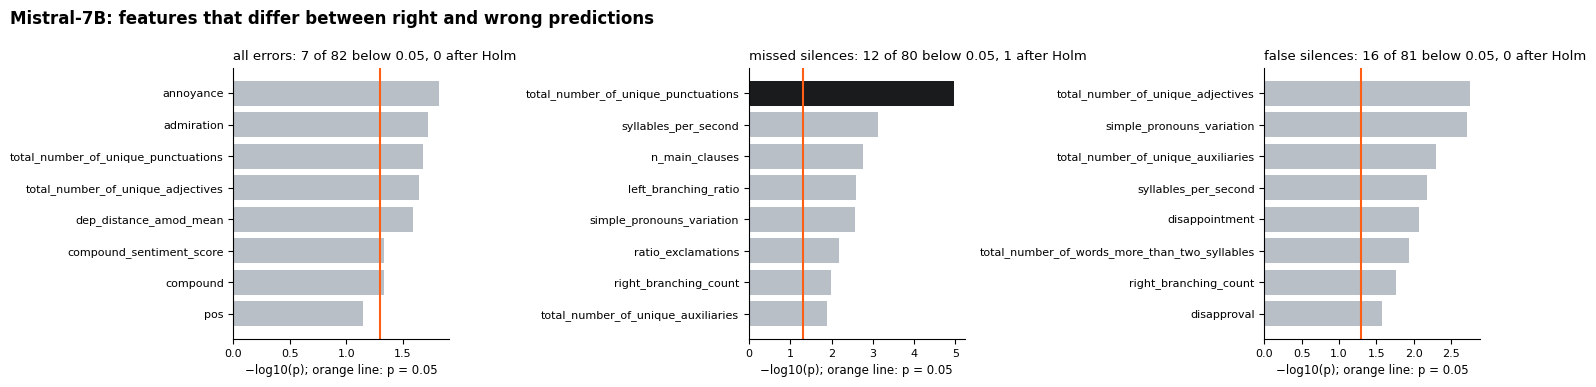

In [17]:
def analyse(file):
    predicted = pd.read_csv(DATA / file)["predicted"].to_numpy()
    return {name: error_analysis.compare(test, thesis_selection, predicted, classes) for name, classes in error_analysis.GROUPS.items()}

errors = {"BERT-Large": analyse("predictions_bert_linear.csv"), "Mistral-7B": analyse("predictions_mistral_linear.csv")}
for model, parts in errors.items():
    error_analysis.plot(parts, f"{model}: features that differ between right and wrong predictions")
    plt.show()

In [18]:
table = pd.concat({(model, part): r for model, parts in errors.items() for part, r in parts.items()}, names=["model", "errors", "rank"])
table.round(6).to_csv(RESULTS / "error_analysis.csv")
print("Features that pass the Holm correction:")
table[table["p_holm"] < 0.05].style.format({"p": "{:.6f}", "p_holm": "{:.4f}", "mean_correct": "{:.2f}", "mean_wrong": "{:.2f}"})

Features that pass the Holm correction:


The same structural features come up for both models, in the same direction: missed silences follow faster lines with more clauses,
false silences follow slower and simpler ones.

In [19]:
structure = ["syllables_per_second", "right_branching_count", "n_main_clauses", "total_number_of_unique_punctuations", "total_number_of_unique_auxiliaries"]
rows = table[table["feature"].isin(structure)].reset_index().query("errors != 'all errors'")
rows["in errors"] = rows["in_errors"] + " (p = " + rows["p"].map("{:.4f}".format) + ")"
rows.pivot(index="feature", columns=["model", "errors"], values="in errors")

model                                         BERT-Large                      \
errors                                   missed silences      false silences   
feature                                                                        
n_main_clauses                       higher (p = 0.0136)  lower (p = 0.0067)   
right_branching_count                higher (p = 0.0192)  lower (p = 0.0000)   
syllables_per_second                 higher (p = 0.0079)  lower (p = 0.0052)   
total_number_of_unique_auxiliaries   higher (p = 0.1803)  lower (p = 0.0128)   
total_number_of_unique_punctuations  higher (p = 0.0166)  lower (p = 0.0232)   

model                                         Mistral-7B                      
errors                                   missed silences      false silences  
feature                                                                       
n_main_clauses                       higher (p = 0.0017)  lower (p = 0.1010)  
right_branching_count                higher (p = 0.0101)  lower (p = 0.0171)  
syllables_per_second                 higher (p = 0.0008)  lower (p = 0.0065)  
total_number_of_unique_auxiliaries   higher (p = 0.0128)  lower (p = 0.0049)  
total_number_of_unique_punctuations  higher (p = 0.0000)  lower (p = 0.5074)

## 8 All models

In [20]:
summary = pd.DataFrame(results).T.sort_values("accuracy", ascending=False)
summary["reads"] = ["both lines" if n.startswith(("BERT", "Mistral")) else "line 1 (trained on both)" if n.startswith("TF") else "line 1" for n in summary.index]
summary[["reads", "inputs", "accuracy", "roc_auc", "macro_f1"]].to_csv(RESULTS / "all_models.csv", float_format="%.6f")
summary[["reads", "inputs", "accuracy", "roc_auc", "macro_f1"]].round(4)

,reads,inputs,accuracy,roc_auc,macro_f1
"Mistral-7B, RBF SVM",both lines,4096.0,0.6677,0.7254,0.6675
"BERT-Large, RBF SVM",both lines,4096.0,0.6500,0.7044,0.6493
"82 selected features, linear SVM",line 1,82.0,0.6268,0.6779,0.6264
"All 287 features, linear SVM",line 1,287.0,0.6122,0.6794,0.6117
"Mistral-7B, linear SVM",both lines,4096.0,0.5852,0.6296,0.5852
"TF-IDF baseline, linear SVM",line 1 (trained on both),32483.0,0.5705,0.6084,0.5686
"BERT-Large, linear SVM",both lines,4096.0,0.5605,0.5950,0.5605


## 9 Checks made after the thesis

These were run while preparing this repository. They are not in the thesis, and nothing was tuned on their results.

**1. Same information for the baseline.** The thesis baseline was trained on both lines and tested on one; the features use line 1 only;
the transformers use both lines. *Needs the subtitles.*

In [21]:
checks = {}
if HAVE_SUBTITLES:
    for name, text in {"TF-IDF, line 1 → line 1": first, "TF-IDF, both lines → both lines": both}.items():
        svm, C = models.tune_linear_svm(np.concatenate([text["train"], text["validation"]]), trainval[TARGET], models.with_tfidf)
        s = models.scores(test[TARGET], svm.predict(text["test"]), svm.decision_function(text["test"]))
        checks[name] = {"accuracy": s["accuracy"], "roc_auc": s["roc_auc"]}

**2. Speech rate.** It uses the line's time on screen. How far does it carry the result?

In [22]:
for name, columns in {"speech rate alone (1 feature)": ["syllables_per_second"],
                      "82 features without speech rate (81)": [c for c in selected if c != "syllables_per_second"]}.items():
    svm, C = models.tune_linear_svm(trainval[columns].to_numpy(), trainval[TARGET])
    X = test[columns].to_numpy()
    s = models.scores(test[TARGET], svm.predict(X), svm.decision_function(X))
    checks[name] = {"accuracy": s["accuracy"], "roc_auc": s["roc_auc"]}
checks = pd.DataFrame(checks).T
checks.round(6).to_csv(RESULTS / "checks.csv")
checks.round(4)

,accuracy,roc_auc
"TF-IDF, line 1 → line 1",0.5875,0.5977
"TF-IDF, both lines → both lines",0.6176,0.6552
speech rate alone (1 feature),0.5998,0.6421
82 features without speech rate (81),0.6245,0.6623


**3. Empty and double columns.** How many of the 287 features carry their own information?

In [23]:
constant = [c for c in features if everything[c].nunique() == 1]
rest = everything[[c for c in features if c not in constant]].round(9).T
double = rest.index[rest.duplicated()].tolist()
print(len(constant), "features have the same value on every line:", len([c for c in constant if c in GROUPS["Affect"]]), "of them in the affect group")
print(len(double), "features repeat another one exactly")
print(len(features) - len(constant) - len(double), "distinct features remain")

22 features have the same value on every line: 20 of them in the affect group
9 features repeat another one exactly
256 distinct features remain


**4. Neighbouring lines.** The split is random over lines, so the reply of one pair can be the first line of another. How many test pairs
share a line with the training or validation part? *Needs the subtitles.*

In [24]:
if HAVE_SUBTITLES:
    seen = pd.concat([pair_tables["train"], pair_tables["validation"]])
    replies = set(zip(seen["file_name"], seen["sub2_start_sec"]))
    starts = set(zip(seen["file_name"], seen["sub1_start_sec"]))
    t = pair_tables["test"]
    shared = [(f, a) in replies or (f, b) in starts for f, a, b in zip(t["file_name"], t["sub1_start_sec"], t["sub2_start_sec"])]
    print(f"{np.mean(shared):.0%} of the test pairs share a line with a training or validation pair")

89% of the test pairs share a line with a training or validation pair
